# 03 — SimSiam (T8) : détection d'anomalies sans étiquettes

**Idée (analogie)** : on montre au réseau *deux photos différentes de la même pièce saine* (recadrée, légèrement éclairée autrement) et on lui apprend à dire « c'est la même chose ». Il n'a vu **que des pièces saines**. Au test, une pièce avec défaut sort de tout ce qu'il connaît : elle est « loin » de l'album de pièces saines.

**Où exécuter quoi**
- 💻 **Local (Windows)** : écrire/éditer `src/models/simsiam.py`, commit, push. *(déjà fait si tu as suivi les étapes git)*
- ☁️ **Colab (GPU T4)** : **tout ce notebook** (entraînement, extraction, scoring) → ça demande un GPU.

## 0. Setup — ☁️ Colab
**Pourquoi** : Colab repart de zéro à chaque session. On clone/pull le repo pour récupérer la dernière version de `src/` (écrite en local), et on monte Drive pour que les **checkpoints survivent** aux déconnexions.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 31 (delta 10), reused 25 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 9.33 KiB | 3.11 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


## 1. Imports + seeds
**Pourquoi** : seeds fixées (torch, numpy, random) = résultats reproductibles et comparables au VAE (guide, étape 0). On importe `data.py` (déjà fait) et le modèle SimSiam.

In [2]:
import sys, random, time
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score

sys.path.insert(0, REPO)
from src.data import list_train_val, list_test, MVTecDataset
from src.models.simsiam import SimSiam, TwoViews, simsiam_loss

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. Configuration
**Pourquoi ces choix**
- `IMG_SIZE = 224` : `layer3` de ResNet-18 divise la taille par 16 → carte **14×14** (à 128 px ce serait 8×8, trop grossier pour une carte d'anomalie). C'est aussi la taille de DINO (notebook 04). ⚠️ Le VAE était en 128 : **à dire explicitement dans le rapport** (piège « comparer des résolutions différentes sans le dire »).
- `EPOCHS = 200` : peu d'images (~200-250 par catégorie), donc une epoch = quelques itérations seulement.
- `K_MAIN = 3` : fixé **à l'avance** (on ne le choisit pas en regardant le test → pas de fuite). On rapporte quand même k = 1, 3, 5 pour l'ablation du guide.
- `SIGMA = 4` : lissage gaussien des cartes (guide, étape 2), sinon AUROC pixel faussement bas.

In [3]:
ROOT = DATA_ROOT               # vient de config.py (/content/mvtec)
CATS = CATEGORIES              # vient de config.py

IMG_SIZE = 224
BS, EPOCHS, LR = 32, 200, 0.03
K_LIST, K_MAIN = [1, 3, 5], 3
SIGMA = 4

RES_DIR = f"{REPO}/results"    # CKPT_DIR n'est plus redéfini : on garde celui de config.py
os.makedirs(RES_DIR, exist_ok=True)
print("Checkpoints ->", CKPT_DIR)

Checkpoints -> /content/drive/MyDrive/anomaly_mvtec/checkpoints


## 3. Entraînement SimSiam
**Pourquoi chaque ingrédient**
- **2 vues augmentées** de la même image (`RandomResizedCrop 0.6–1`, `ColorJitter` léger, flou) : c'est le signal d'apprentissage, sans étiquette. **Pas de flip/rotation** : l'orientation compte (ex. `cable`), et on évite tout ce qui ressemble à un défaut.
- **Stop-gradient** (`z.detach()` dans la perte) : sans ça, le réseau « triche » en sortant toujours le même vecteur → **effondrement (collapse)**.
- **Moniteur de collapse** : écart-type des embeddings L2-normalisés. Sain ≈ `1/√d` (= 0.044 pour d = 512). S'il tombe vers 0 → collapse (guide, étape 4).
- **Deux runs par catégorie** : `scratch` (respecte « sans étiquettes ») vs `ImageNet` (ablation demandée par le guide). Poids sauvegardés sur Drive.
- **Train uniquement** (80 % de `train/good`) : `val_normal` est réservé au seuil (T9), le test n'est jamais touché.

In [4]:
def train_simsiam(cat, pretrained, epochs=EPOCHS, bs=BS):
    set_seed()
    train_items, _ = list_train_val(ROOT, cat)
    dl = DataLoader(TwoViews(train_items, IMG_SIZE), batch_size=bs, shuffle=True,
                    drop_last=True, num_workers=2)
    model = SimSiam(pretrained=pretrained).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"loss": [], "std": []}
    ref = 1 / np.sqrt(512)
    for ep in range(epochs):
        model.train(); ls, ss = [], []
        for x1, x2 in dl:
            x1, x2 = x1.to(device), x2.to(device)
            p1, p2, z1, z2 = model(x1, x2)
            loss = simsiam_loss(p1, p2, z1, z2)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            ls.append(loss.item())
            ss.append(F.normalize(z1, dim=1).std(0).mean().item())
        sched.step()
        hist["loss"].append(float(np.mean(ls))); hist["std"].append(float(np.mean(ss)))
        if (ep + 1) % 25 == 0 or ep == 0:
            flag = "  ⚠️ COLLAPSE ?" if hist["std"][-1] < 0.3 * ref else ""
            print(f"  ep {ep+1:3d} | loss {hist['loss'][-1]:.4f} | std {hist['std'][-1]:.4f} (cible ~{ref:.4f}){flag}")
    return model, hist

## 4. Scoring : banque mémoire + k-NN
**Pourquoi** : SimSiam ne produit pas directement un score d'anomalie. On utilise la méthode du guide :
1. On extrait les features de **toutes les images d'entraînement** = la *banque mémoire* (l'album de pièces saines).
2. Pour une image test, on cherche **la photo la plus ressemblante** de l'album. Si même la meilleure ressemble mal → anomalie.
- **Score image** : distance k-NN sur l'embedding global (512-d, L2-normalisé).
- **Carte d'anomalie** : même principe **par patch** sur `layer3` (14×14 patchs de 256-d) → upsample bilinéaire → lissage gaussien. Score image « carte » = **max** de la carte.
- La banque ne contient **que le train** (pas `val_normal`, pas le test) → pas de fuite de données.

In [5]:
@torch.no_grad()
def extract(model, items, bs=32):
    ds = MVTecDataset(items, IMG_SIZE, imagenet_norm=True)
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2)
    model.eval()
    F3, EMB, LAB, MSK = [], [], [], []
    for x, y, m in dl:
        f3, emb = model.features(x.to(device))
        F3.append(f3.cpu()); EMB.append(F.normalize(emb, dim=1).cpu())
        LAB.append(torch.as_tensor(y)); MSK.append(m)
    return torch.cat(F3), torch.cat(EMB), torch.cat(LAB).numpy(), torch.cat(MSK)

@torch.no_grad()
def knn_dist(q, bank, k=1, chunk=1024):
    out = []
    for i in range(0, len(q), chunk):
        d = torch.cdist(q[i:i+chunk].to(device), bank)
        out.append(d.topk(k, dim=1, largest=False).values.mean(1).cpu())
    return torch.cat(out)

def score_category(model, cat):
    train_items, _ = list_train_val(ROOT, cat)
    test_items = list_test(ROOT, cat)
    f3_tr, emb_tr, _, _ = extract(model, train_items)
    f3_te, emb_te, labels, masks = extract(model, test_items)

    # --- niveau image : k-NN sur l'embedding global
    bank_emb = emb_tr.to(device)
    emb_scores = {k: knn_dist(emb_te, bank_emb, k).numpy() for k in K_LIST}

    # --- niveau pixel : k-NN par patch sur layer3
    N, C, h, w = f3_tr.shape
    bank_p = f3_tr.permute(0, 2, 3, 1).reshape(-1, C).to(device)
    M = f3_te.shape[0]
    q = f3_te.permute(0, 2, 3, 1).reshape(-1, C)
    d = knn_dist(q, bank_p, k=1).reshape(M, 1, h, w)
    maps = F.interpolate(d, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[:, 0].numpy()
    maps = np.stack([gaussian_filter(m, sigma=SIGMA) for m in maps])
    return dict(labels=labels, masks=masks[:, 0].numpy(), emb_scores=emb_scores,
                maps=maps, map_score=maps.reshape(M, -1).max(1))

## 5. Évaluation commune
**Pourquoi** : même fonction `evaluate` que pour le VAE (cadre d'évaluation commun, guide étape 2) pour que le tableau final VAE vs SimSiam vs DINO soit comparable. AUROC image = « sait-on dire défectueux/sain ? », AUROC pixel = « sait-on **localiser** le défaut ? ».
On rapporte les deux scores image (embedding global et max de carte) **sans choisir le meilleur après coup sur le test**.

In [6]:
def evaluate(labels, img_scores, masks, maps):
    img_auc = roc_auc_score(labels, img_scores)
    pix_auc = roc_auc_score(masks.flatten() > 0, maps.flatten())
    return img_auc, pix_auc

## 6. Lancer toutes les expériences (3 catégories × scratch/ImageNet)
**Pourquoi** : une ligne par (modèle, catégorie) dans un DataFrame, comme demandé par le guide. ⏱️ Compte ~1 h sur T4 pour les 6 runs ; checkpoints sur Drive.

In [7]:
rows, RUNS, HIST = [], {}, {}
for cat in CATS:
    for pre in [False, True]:
        tag = "SimSiam-ImageNet" if pre else "SimSiam-scratch"
        print(f"\n=== {tag} | {cat} ===")
        t0 = time.time()
        model, hist = train_simsiam(cat, pre)
        torch.save(model.state_dict(), f"{CKPT_DIR}/{tag}_{cat}.pt")
        out = score_category(model, cat)
        RUNS[(cat, tag)], HIST[(cat, tag)] = out, hist

        row = {"model": tag, "category": cat}
        for k in K_LIST:
            row[f"img_auc_knn{k}"] = roc_auc_score(out["labels"], out["emb_scores"][k])
        row["img_auc_mapmax"], row["pix_auc"] = evaluate(out["labels"], out["map_score"], out["masks"], out["maps"])
        rows.append(row)
        print({k: round(v, 3) for k, v in row.items() if isinstance(v, float)}, f"| {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache()

df = pd.DataFrame(rows)
df


=== SimSiam-scratch | carpet ===
  ep   1 | loss 0.0033 | std 0.0447 (cible ~0.0442)
  ep  25 | loss -0.6827 | std 0.0308 (cible ~0.0442)
  ep  50 | loss -0.7320 | std 0.0291 (cible ~0.0442)
  ep  75 | loss -0.7710 | std 0.0268 (cible ~0.0442)
  ep 100 | loss -0.7695 | std 0.0269 (cible ~0.0442)
  ep 125 | loss -0.7584 | std 0.0297 (cible ~0.0442)
  ep 150 | loss -0.7820 | std 0.0260 (cible ~0.0442)
  ep 175 | loss -0.7877 | std 0.0262 (cible ~0.0442)
  ep 200 | loss -0.7745 | std 0.0270 (cible ~0.0442)
{'img_auc_knn1': np.float64(0.487), 'img_auc_knn3': np.float64(0.461), 'img_auc_knn5': np.float64(0.427), 'img_auc_mapmax': np.float64(0.872), 'pix_auc': np.float64(0.877)} | 798s

=== SimSiam-ImageNet | carpet ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


  ep   1 | loss 0.0005 | std 0.0449 (cible ~0.0442)
  ep  25 | loss -0.8783 | std 0.0336 (cible ~0.0442)
  ep  50 | loss -0.8146 | std 0.0232 (cible ~0.0442)
  ep  75 | loss -0.8299 | std 0.0212 (cible ~0.0442)
  ep 100 | loss -0.8423 | std 0.0223 (cible ~0.0442)
  ep 125 | loss -0.8427 | std 0.0237 (cible ~0.0442)
  ep 150 | loss -0.8432 | std 0.0223 (cible ~0.0442)
  ep 175 | loss -0.8618 | std 0.0214 (cible ~0.0442)
  ep 200 | loss -0.8637 | std 0.0209 (cible ~0.0442)
{'img_auc_knn1': np.float64(0.293), 'img_auc_knn3': np.float64(0.291), 'img_auc_knn5': np.float64(0.287), 'img_auc_mapmax': np.float64(0.511), 'pix_auc': np.float64(0.895)} | 797s

=== SimSiam-scratch | screw ===
  ep   1 | loss -0.0025 | std 0.0448 (cible ~0.0442)
  ep  25 | loss -0.9295 | std 0.0442 (cible ~0.0442)
  ep  50 | loss -0.9672 | std 0.0442 (cible ~0.0442)
  ep  75 | loss -0.9717 | std 0.0443 (cible ~0.0442)
  ep 100 | loss -0.9711 | std 0.0443 (cible ~0.0442)
  ep 125 | loss -0.9729 | std 0.0444 (cible ~0

,model,category,img_auc_knn1,img_auc_knn3,img_auc_knn5,img_auc_mapmax,pix_auc
0,SimSiam-scratch,carpet,0.487159,0.461477,0.426966,0.871589,0.876716
1,SimSiam-ImageNet,carpet,0.292536,0.290530,0.287319,0.510835,0.895466
2,SimSiam-scratch,screw,0.468129,0.513835,0.512400,0.564255,0.939675
3,SimSiam-ImageNet,screw,0.598278,0.541299,0.518754,0.810002,0.980809
4,SimSiam-scratch,cable,0.772489,0.766679,0.759183,0.847076,0.945263
5,SimSiam-ImageNet,cable,0.906109,0.894303,0.887931,0.908733,0.970448


## 7. Courbes de collapse + exemples de heatmaps
**Pourquoi** : (1) prouver dans le rapport que SimSiam ne s'est **pas** effondré (std proche de 1/√d) ; (2) regarder des succès **et** des échecs (guide : « montre aussi les échecs »). Ici l'échantillon est aléatoire ; la sélection propre succès/échecs sera faite en T9 (notebook 05).

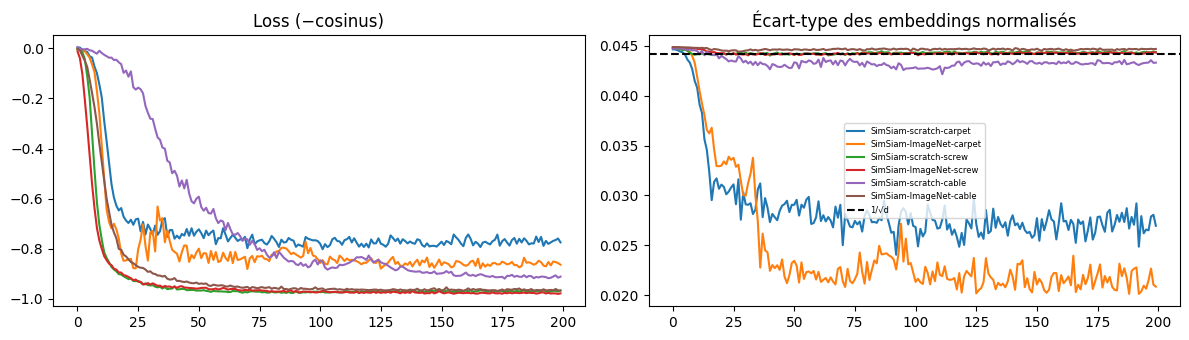

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for (cat, tag), h in HIST.items():
    ax[0].plot(h["loss"], label=f"{tag}-{cat}"); ax[1].plot(h["std"], label=f"{tag}-{cat}")
ax[1].axhline(1/np.sqrt(512), ls="--", c="k", label="1/√d")
ax[0].set_title("Loss (−cosinus)"); ax[1].set_title("Écart-type des embeddings normalisés")
ax[1].legend(fontsize=6); plt.tight_layout()
plt.savefig(f"{RES_DIR}/simsiam_collapse.png", dpi=150); plt.show()

In [9]:
def show_examples(cat, tag, n=3):
    out = RUNS[(cat, tag)]
    ds = MVTecDataset(list_test(ROOT, cat), IMG_SIZE)           # sans normalisation : pour l'affichage
    idx = np.where(out["labels"] == 1)[0]
    idx = np.random.RandomState(0).choice(idx, n, replace=False)
    fig, ax = plt.subplots(n, 4, figsize=(12, 3 * n))
    for r, i in enumerate(idx):
        img, _, m = ds[i]; img = img.permute(1, 2, 0).numpy(); hm = out["maps"][i]
        ax[r, 0].imshow(img); ax[r, 1].imshow(m[0], cmap="gray")
        ax[r, 2].imshow(hm, cmap="jet"); ax[r, 3].imshow(img); ax[r, 3].imshow(hm, cmap="jet", alpha=0.5)
        for a in ax[r]: a.axis("off")
    for a, t in zip(ax[0], ["image", "masque GT", "heatmap", "superposition"]): a.set_title(t)
    plt.suptitle(f"{tag} — {cat}"); plt.tight_layout()
    plt.savefig(f"{RES_DIR}/simsiam_examples_{tag}_{cat}.png", dpi=150); plt.show()

for cat in CATS:
    show_examples(cat, "SimSiam-ImageNet")

Output hidden; open in https://colab.research.google.com to view.

## 8. Sauvegarde des résultats
**Pourquoi** : le CSV (petit) est versionné dans `results/` pour construire le tableau final ; les poids `.pt` restent sur Drive (trop lourds pour git).

In [10]:
df.to_csv(f"{RES_DIR}/simsiam_results.csv", index=False)
df.round(3)

,model,category,img_auc_knn1,img_auc_knn3,img_auc_knn5,img_auc_mapmax,pix_auc
0,SimSiam-scratch,carpet,0.487,0.461,0.427,0.872,0.877
1,SimSiam-ImageNet,carpet,0.293,0.291,0.287,0.511,0.895
2,SimSiam-scratch,screw,0.468,0.514,0.512,0.564,0.940
3,SimSiam-ImageNet,screw,0.598,0.541,0.519,0.810,0.981
4,SimSiam-scratch,cable,0.772,0.767,0.759,0.847,0.945
5,SimSiam-ImageNet,cable,0.906,0.894,0.888,0.909,0.970


## 9. (Optionnel) Push depuis Colab
Sinon : télécharge `results/` + le notebook et fais le push depuis Windows (voir commandes git).
Pour pousser depuis Colab, crée un **token GitHub** (Settings > Developer settings > Personal access tokens, droit `repo`) et ajoute-le dans les *Secrets* de Colab (🔑) sous le nom `GH_TOKEN`.

In [16]:
from google.colab import userdata
token = userdata.get("GH_TOKEN")
!git config user.email "maha.marrakchi@usmba.ac.ma"
!git config user.name "maha-mrrk"
!git add results/simsiam_results.csv results/*.png
!git commit -m "Résultats SimSiam (T8)"
!git push https://{token}@github.com/maha-mrrk/anomaly-mvtec.git main

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
remote: Permission to maha-mrrk/anomaly-mvtec.git denied to maha-mrrk.
fatal: unable to access 'https://github.com/maha-mrrk/anomaly-mvtec.git/': The requested URL returned error: 403
